In [26]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np 
import openpyxl

In [27]:
df = pd.read_excel('/Users/ypragnesh/Desktop/fcd/codes/Graphs/NSTR_WET.xlsx',sheet_name='SI')

In [28]:
df.head(5)

,Year,Month,Non Vegetation,Very Low,Low,Moderate,High,Very High
0,1995,December,3.1617,10.3653,20.5110,44.4204,88.6941,62.0235
1,2001,December,3.3354,13.4415,28.3446,55.6281,73.4652,54.9612
2,2004,December,6.9327,23.4936,45.6030,59.5341,55.3851,38.2275
3,2006,December,1.9467,12.2400,27.8883,56.0457,77.0463,54.0090
4,2008,December,4.4352,13.7538,31.8870,63.1359,66.9033,49.0608


In [29]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Year            15 non-null     int64  
 1   Month           15 non-null     str    
 2   Non Vegetation  15 non-null     float64
 3   Very Low        15 non-null     float64
 4   Low             15 non-null     float64
 5   Moderate        15 non-null     float64
 6   High            15 non-null     float64
 7   Very High       15 non-null     float64
dtypes: float64(6), int64(1), str(1)
memory usage: 1.1 KB


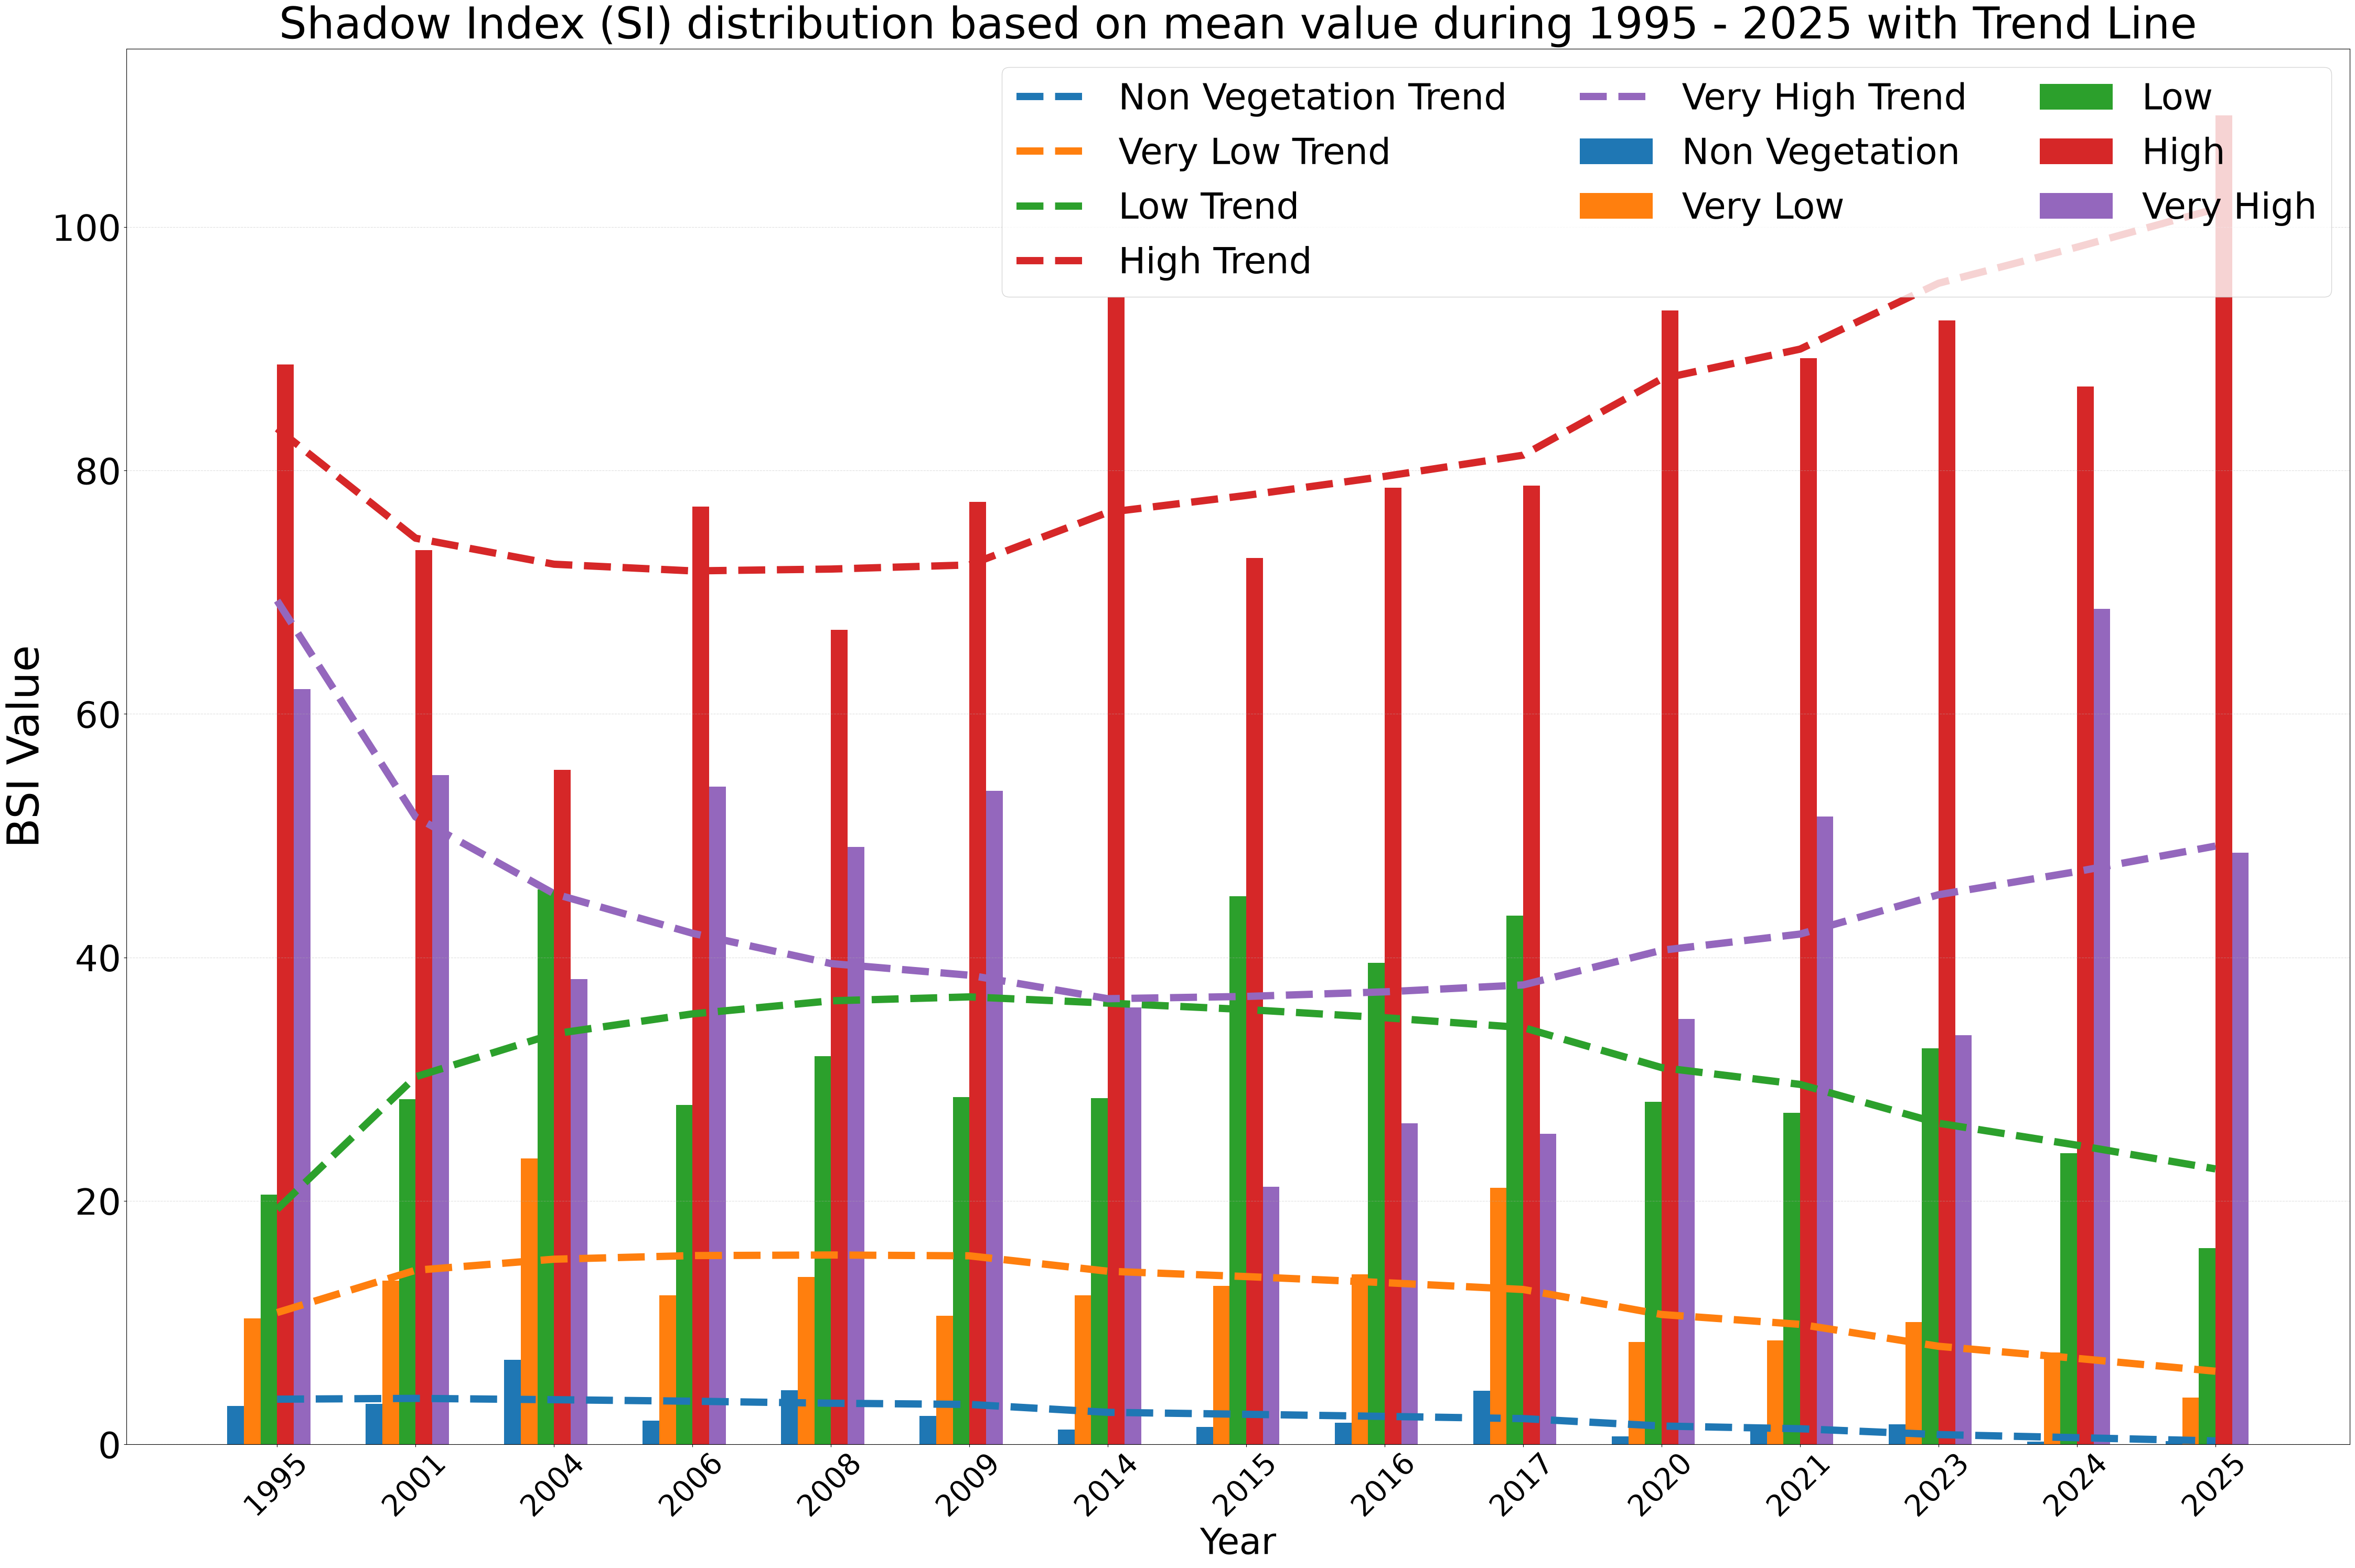

In [30]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Work on a copy of the DataFrame
df = df.copy()

# Remove Month because the analysis is yearly
df["Year"] = pd.to_numeric(df["Year"], errors="coerce")

# Actual FCD classes in your dataset
cols = [
    "Non Vegetation",
    "Very Low",
    "Low",
    "High",
    "Very High"
]

# Convert FCD columns to numeric
for col in cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Remove rows with missing Year values
df = df.dropna(subset=["Year"])

# Calculate yearly mean for each FCD class
df = df.groupby("Year", as_index=False)[cols].mean()
df = df.sort_values("Year").reset_index(drop=True)

# Use actual years for trendline fitting
years = df["Year"].to_numpy(dtype=float)

plt.figure(figsize=(45, 30))

width = 0.12
x = np.arange(len(df))

# Plot bars
for i, col in enumerate(cols):
    plt.bar(
        x + (i - 2.5) * width,
        df[col],
        width,
        label=col
    )

# Plot quadratic trendlines
for col in cols:
    y = df[col].to_numpy(dtype=float)
    valid = np.isfinite(years) & np.isfinite(y)

    if valid.sum() >= 3:
        z = np.polyfit(years[valid], y[valid], 2)
        p = np.poly1d(z)

        plt.plot(
            x,
            p(years),
            linestyle="--",
            linewidth=10,
            label=f"{col} Trend"
        )
'''
plt.xticks(x, df["Year"].astype(int), rotation=45, fontsize=40)
plt.xlabel("Year", fontsize=50)
plt.ylabel("FCD Value", fontsize=50)
'''

#plt.xticks(x, years,fontsize=50)
plt.xticks(x, df["Year"].astype(int), rotation=45, fontsize=40)
plt.yticks(fontsize=50)
plt.xlabel("Year",fontsize=50)
plt.ylabel("BSI Value",fontsize=60)

plt.title("Shadow Index (SI) distribution based on mean value during 1995 - 2025 with Trend Line",fontsize=60)

plt.legend(ncol=3,fontsize=50,loc='upper right')
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()
